In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [3]:
!pip install ultralytics --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 18.6 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.9 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.4 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.8 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 3.4 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 5.5 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 8.1 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 71.8 MB/s eta 0:00:00:00:0100:01


In [4]:
import os
import yaml
from ultralytics import YOLO
from IPython.display import Image, display

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [5]:
def create_yaml_config(yaml_path, dataset_path, class_names):
    data = {
        'train': os.path.join(dataset_path, 'train/images'),
        'val': os.path.join(dataset_path, 'val/images'),
        'test': os.path.join(dataset_path, 'test/images'),
        'newtest': os.path.join(dataset_path, 'newtest/images'),
        'nc': len(class_names),
        'names': class_names
    }
    with open(yaml_path, 'w') as f:
        yaml.dump(data, f, sort_keys=False)

def print_metrics(metrics_obj, model_name, dataset_name, split_name):
    print(f"\n--- {model_name} on {dataset_name} ({split_name} set) ---")
    if not metrics_obj: return
    p = metrics_obj.results_dict['metrics/precision(B)']
    r = metrics_obj.results_dict['metrics/recall(B)']
    map50 = metrics_obj.results_dict['metrics/mAP50(B)']
    map50_95 = metrics_obj.results_dict['metrics/mAP50-95(B)']
    f1 = 2 * (p * r) / (p + r) if (p + r) > 0 else 0
    print(f"{'Precision':<12}: {p}")
    print(f"{'Recall':<12}: {r}")
    print(f"{'F1-Score':<12}: {f1}")
    print(f"{'mAP@50':<12}: {map50}")
    print(f"{'mAP@50-95':<12}: {map50_95}")

In [6]:
# Path to the original dataset
dataset_path_fsod = "/kaggle/input/object-detection-lydia/FSOD/FSOD"

# Path to the MEDIUM model (from the notebook output)
medium_model_path = '/kaggle/input/notebookaf66161e21/fsod_vs_sixray/yolov10m_fsod_60e/weights/best.pt'

# Path to the LARGE model (from the dataset you created)
# This is the corrected path.
large_model_path = '/kaggle/input/yolov10l-fsod-best-pt/best.pt'

# Class names (must match your training)
class_names_fsod = ['laptop', 'umbrella', 'mobile_phone', 'metal_cup', 'portable_charger_1', 'battery', 'portable_charger_2', 'spray_alcohol', 'iron_shoe', 'glass_bottle', 'lighter', 'metal_can', 'pressure_tank', 'drink_bottle', 'nail_clippers', 'scissor', 'straight_knife', 'multi-tool_knife', 'folding_knife', 'utility_knife']

# Create the YAML file
yaml_path = '/kaggle/working/fsod_config.yaml'
create_yaml_config(yaml_path, dataset_path_fsod, class_names_fsod)

--- Evaluating MEDIUM Model (YOLOv10m) ---

--- On Validation Set ---
Ultralytics 8.3.155 🚀 Python-3.11.11 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLOv10m summary (fused): 136 layers, 15,324,748 parameters, 0 gradients, 58.9 GFLOPs


100%|██████████| 755k/755k [00:00<00:00, 18.3MB/s]


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 61.0±33.1 MB/s, size: 225.2 KB)


val: Scanning /kaggle/input/object-detection-lydia/FSOD/FSOD/val/labels... 1233 images, 0 backgrounds, 0 corrupt: 100%|██████████| 1233/1233 [00:03<00:00, 391.74it/s]


WARNING ⚠️ val: Cache directory /kaggle/input/object-detection-lydia/FSOD/FSOD/val is not writeable, cache not saved.


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 78/78 [00:23<00:00,  3.26it/s]
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


                   all       1233       4070      0.817       0.68      0.762      0.541
                laptop        217        269      0.898       0.97      0.977      0.869
              umbrella        179        219      0.872      0.863       0.91      0.642
          mobile_phone        337        540      0.879      0.845      0.922      0.752
             metal_cup        228        270      0.958      0.936      0.977      0.837
    portable_charger_1        149        177      0.858       0.82      0.915       0.66
               battery        319        480      0.779      0.579      0.684      0.397
    portable_charger_2        144        199       0.84      0.794      0.877      0.646
         spray_alcohol        168        249        0.8      0.462      0.589       0.37
             iron_shoe         80        166      0.833      0.608      0.727      0.436
          glass_bottle        174        298      0.794      0.678      0.756      0.486
               lighte

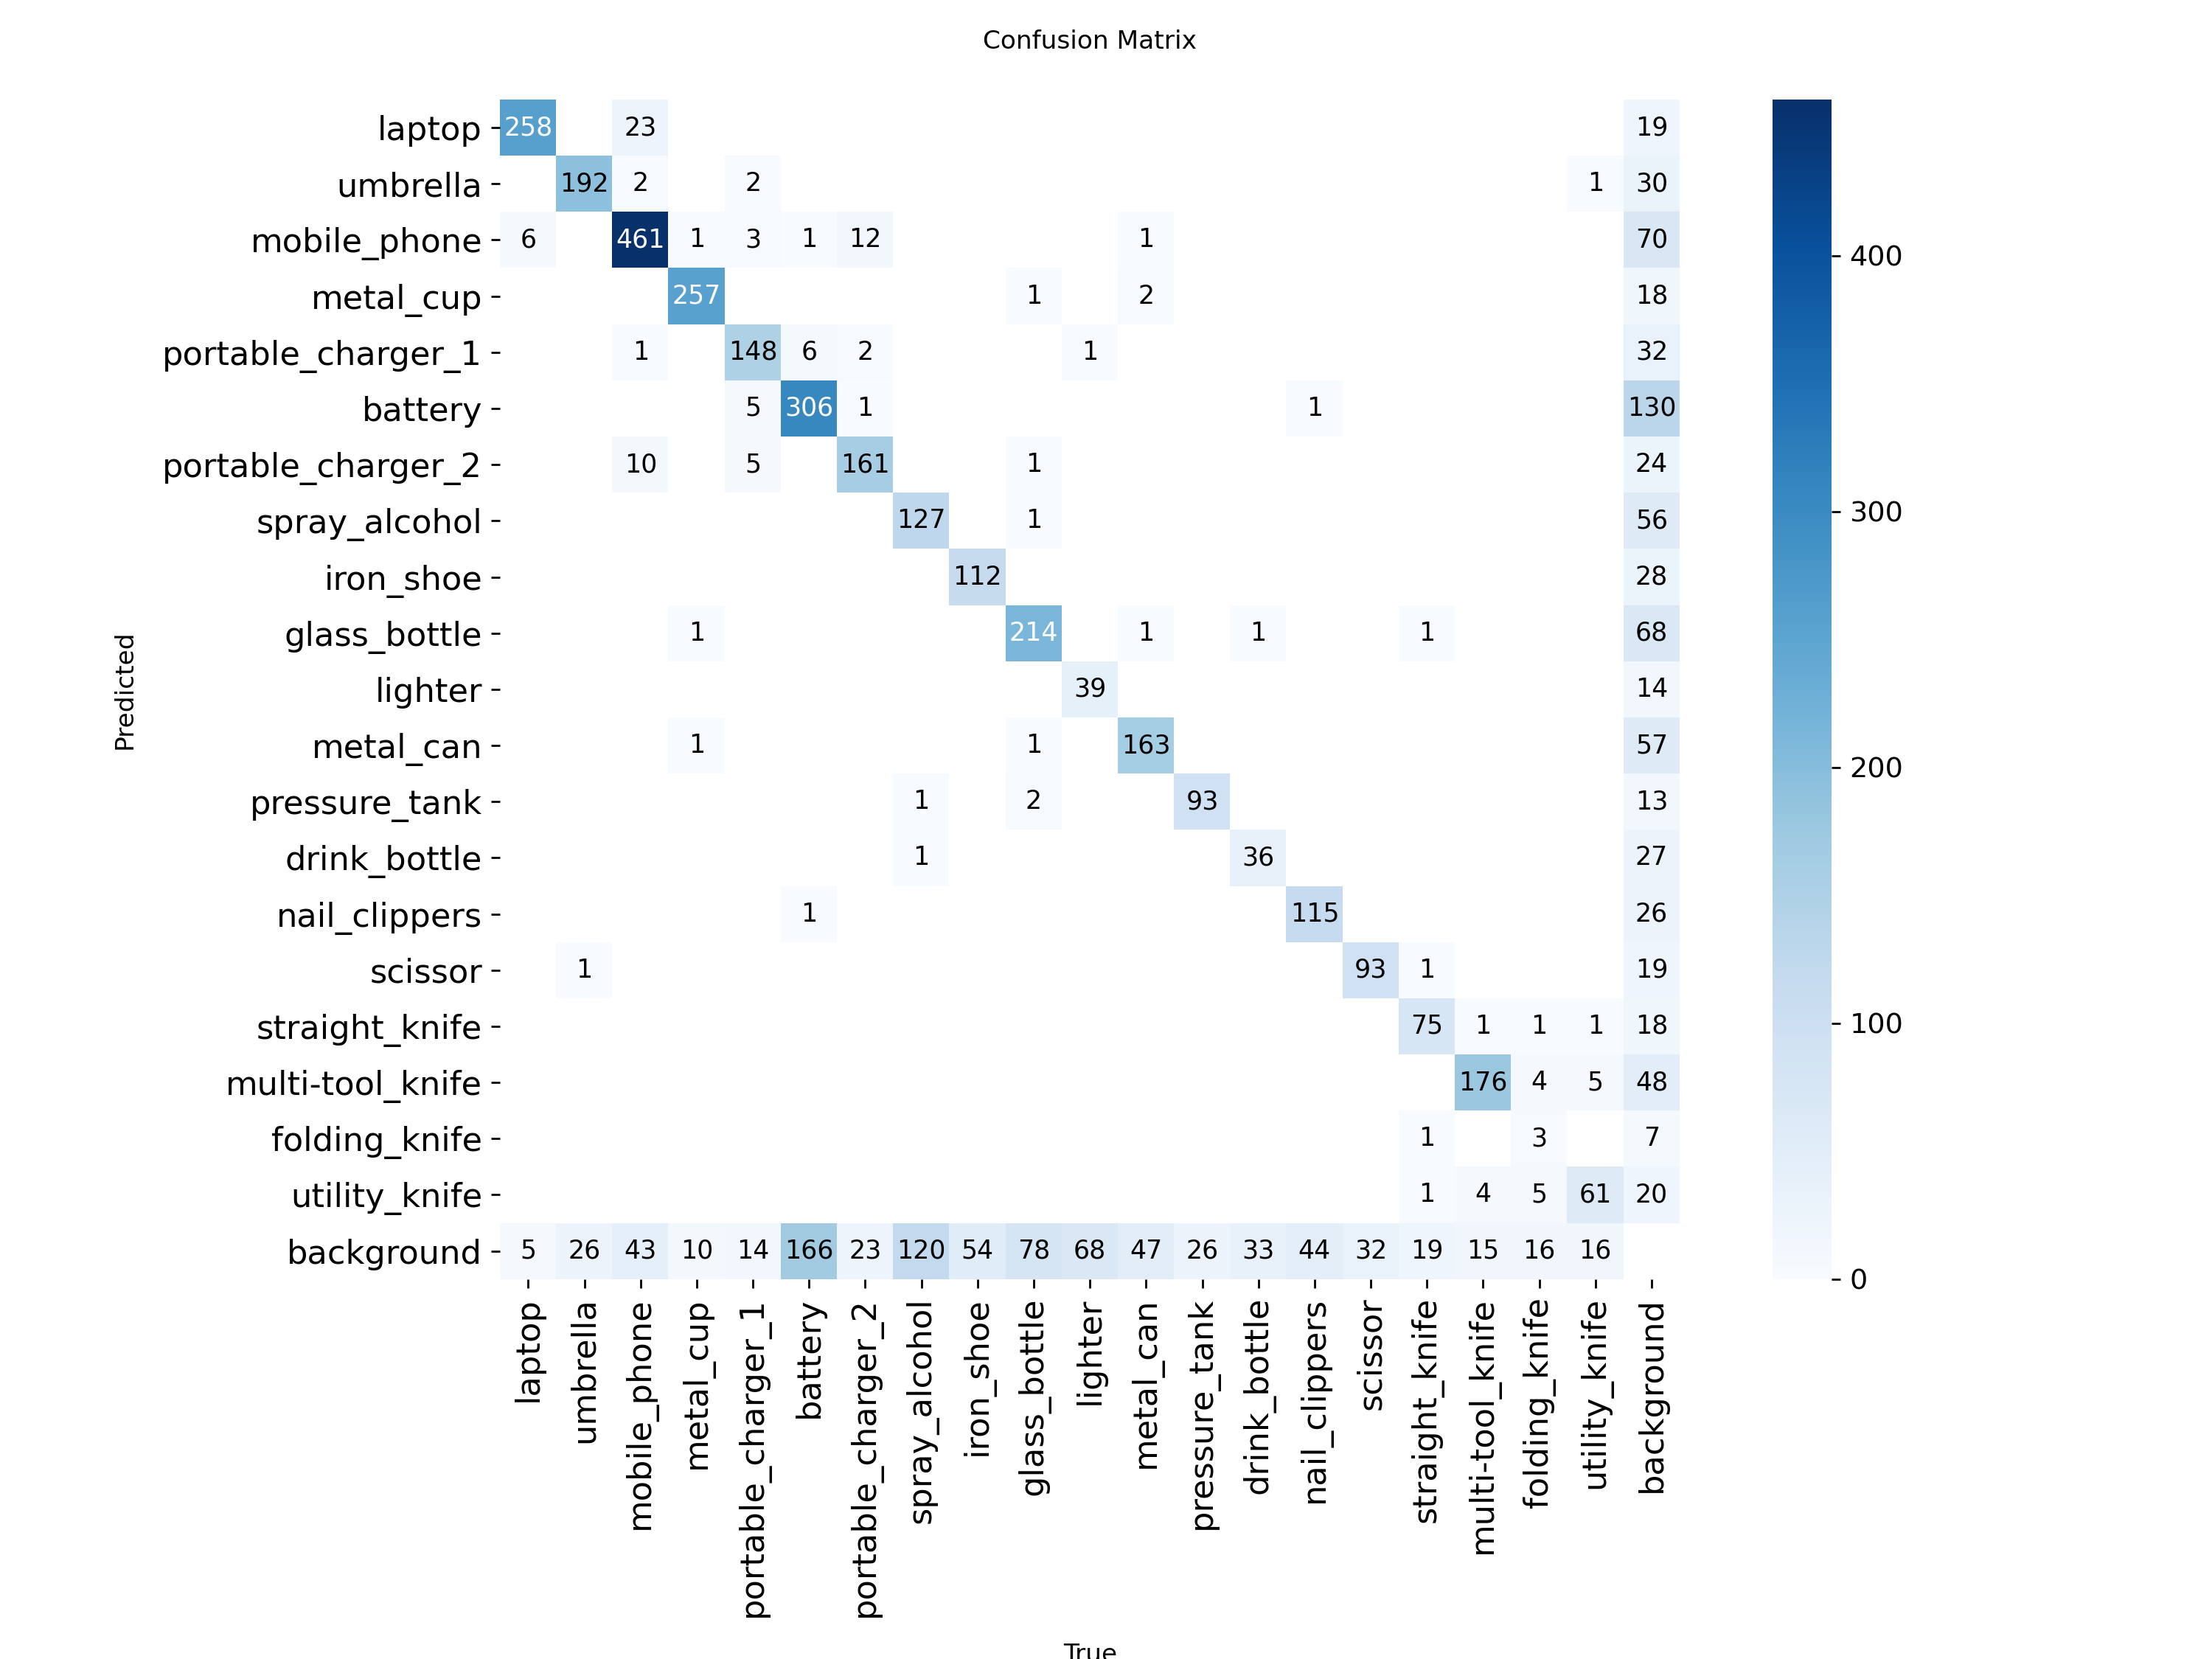

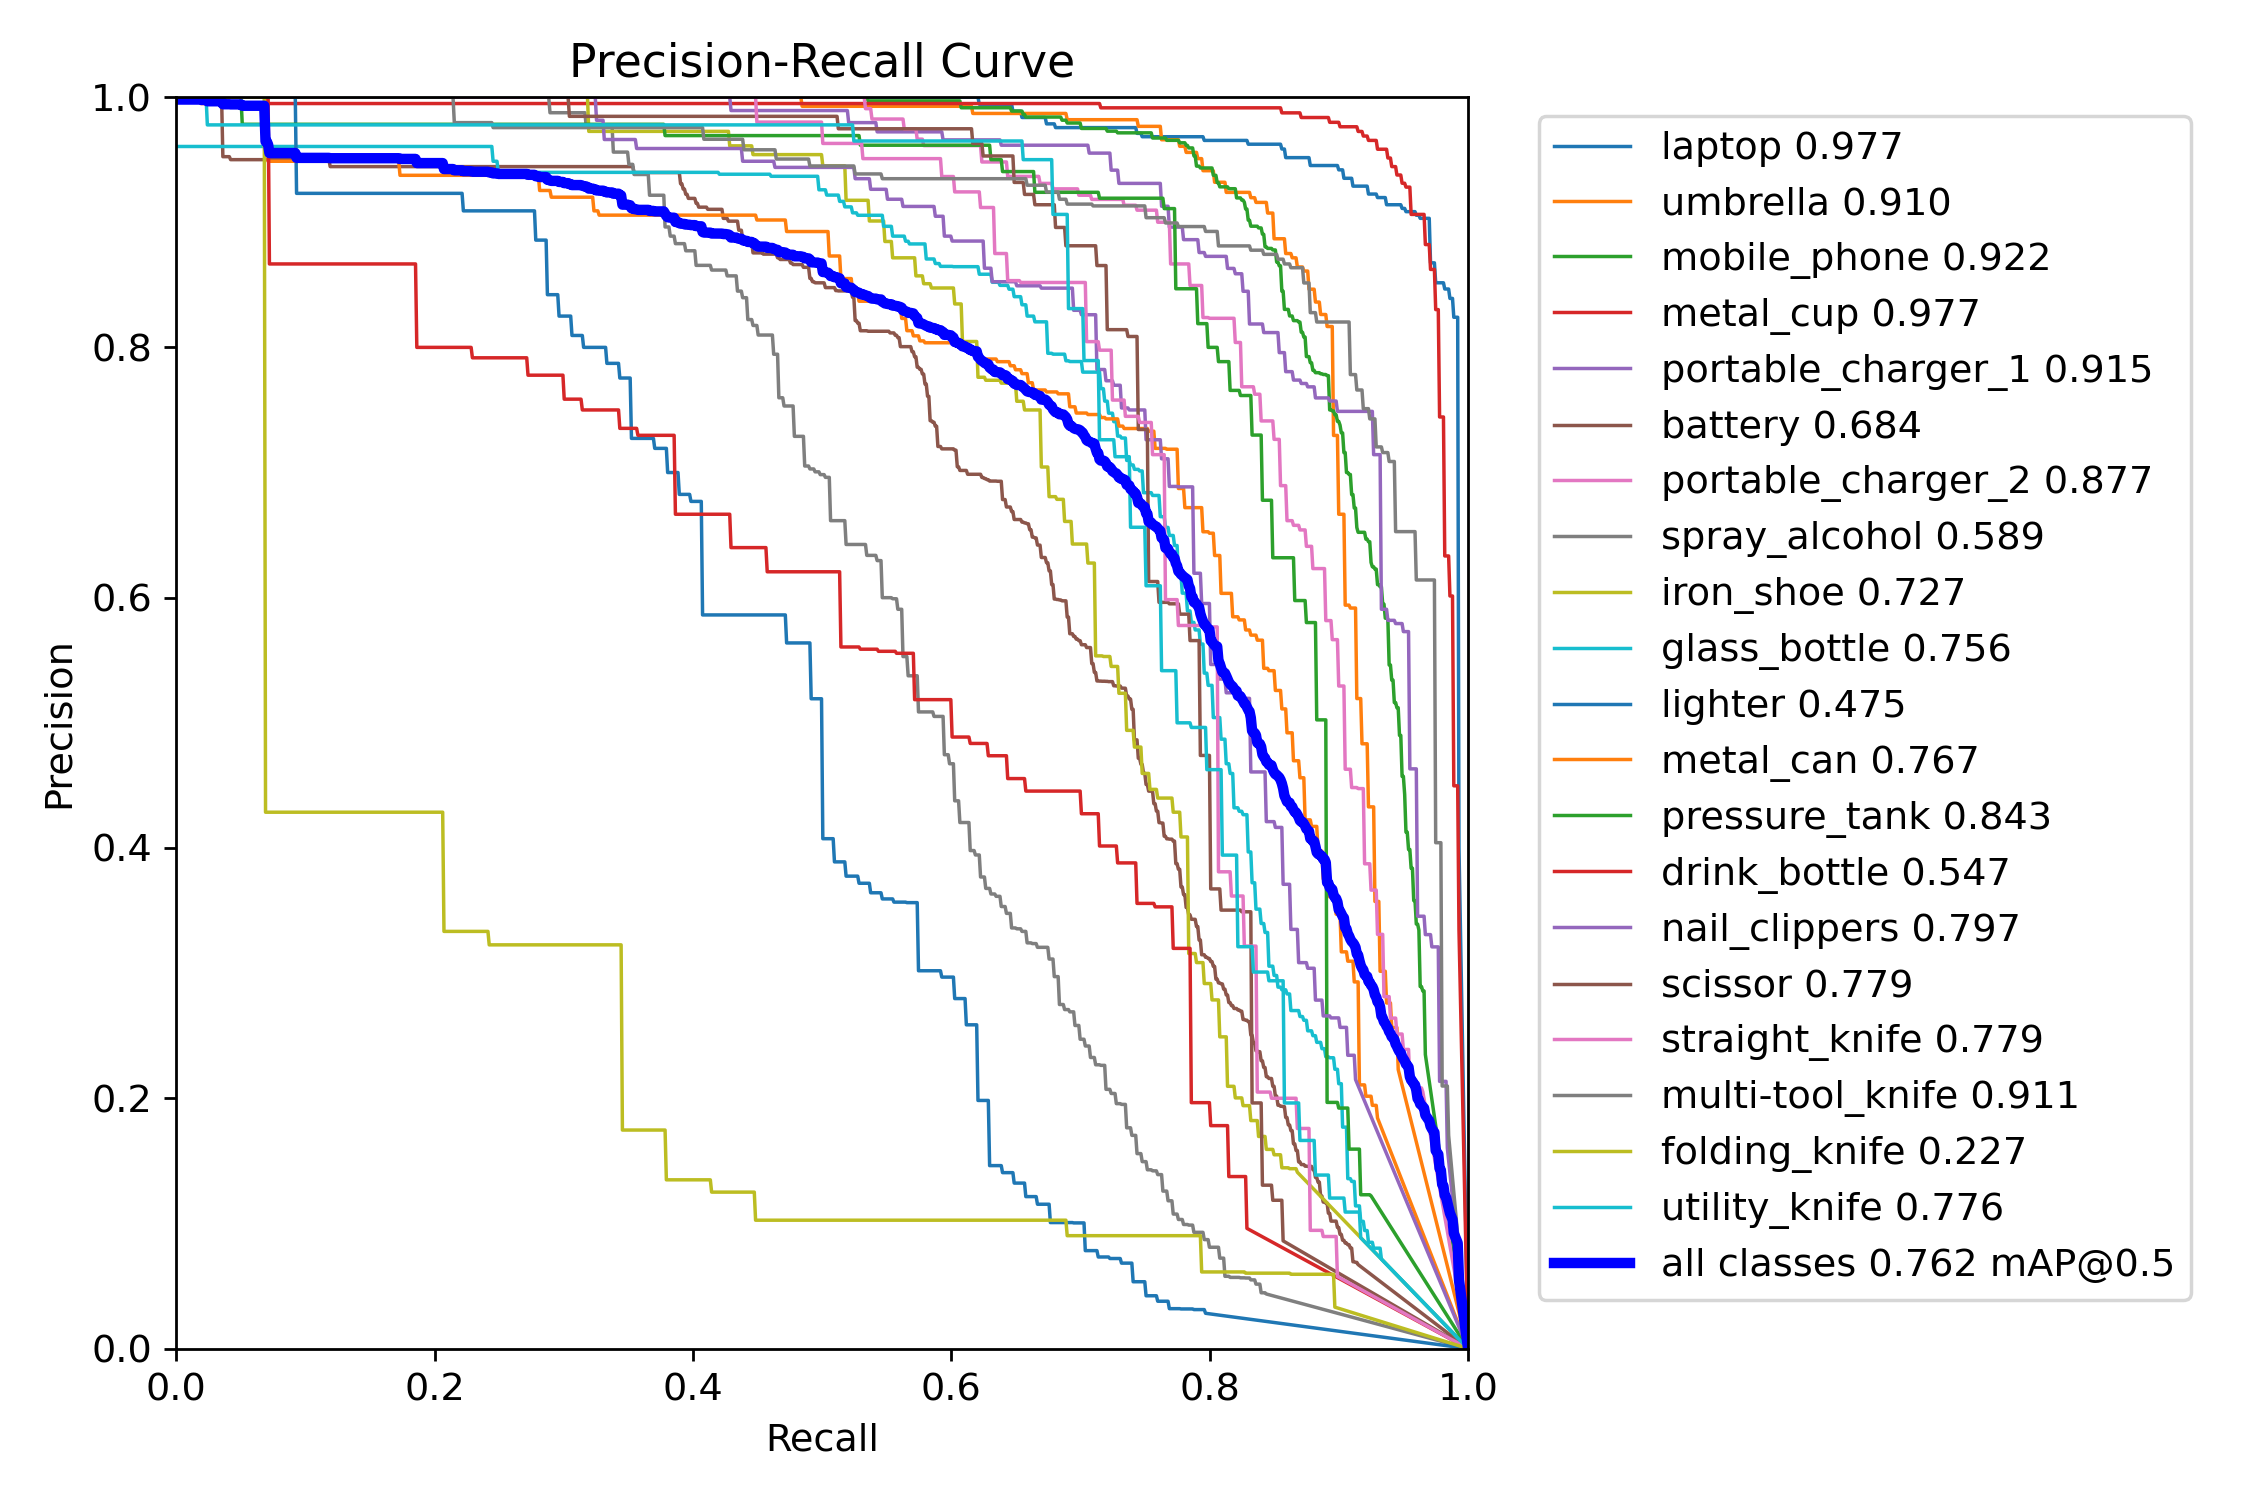


--- On New Test Set ---
Ultralytics 8.3.155 🚀 Python-3.11.11 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 29.0±22.3 MB/s, size: 163.0 KB)


val: Scanning /kaggle/input/object-detection-lydia/FSOD/FSOD/newtest/labels... 1232 images, 1 backgrounds, 0 corrupt: 100%|██████████| 1233/1233 [00:03<00:00, 370.78it/s]


WARNING ⚠️ val: Cache directory /kaggle/input/object-detection-lydia/FSOD/FSOD/newtest is not writeable, cache not saved.


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 78/78 [00:23<00:00,  3.29it/s]
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


                   all       1233       3924      0.795      0.703       0.76      0.541
                laptop        238        282      0.952      0.972      0.979      0.894
              umbrella        174        215      0.877      0.935      0.953      0.676
          mobile_phone        338        531      0.894      0.901      0.945      0.781
             metal_cup        240        269      0.923      0.944      0.973      0.859
    portable_charger_1        147        176      0.834      0.826      0.875      0.636
               battery        308        485      0.712      0.621       0.67      0.382
    portable_charger_2        143        186      0.836      0.849      0.895      0.699
         spray_alcohol        173        244      0.822      0.475      0.578      0.346
             iron_shoe         71        144      0.834      0.629      0.742      0.424
          glass_bottle        165        307      0.781       0.65      0.717       0.46
               lighte

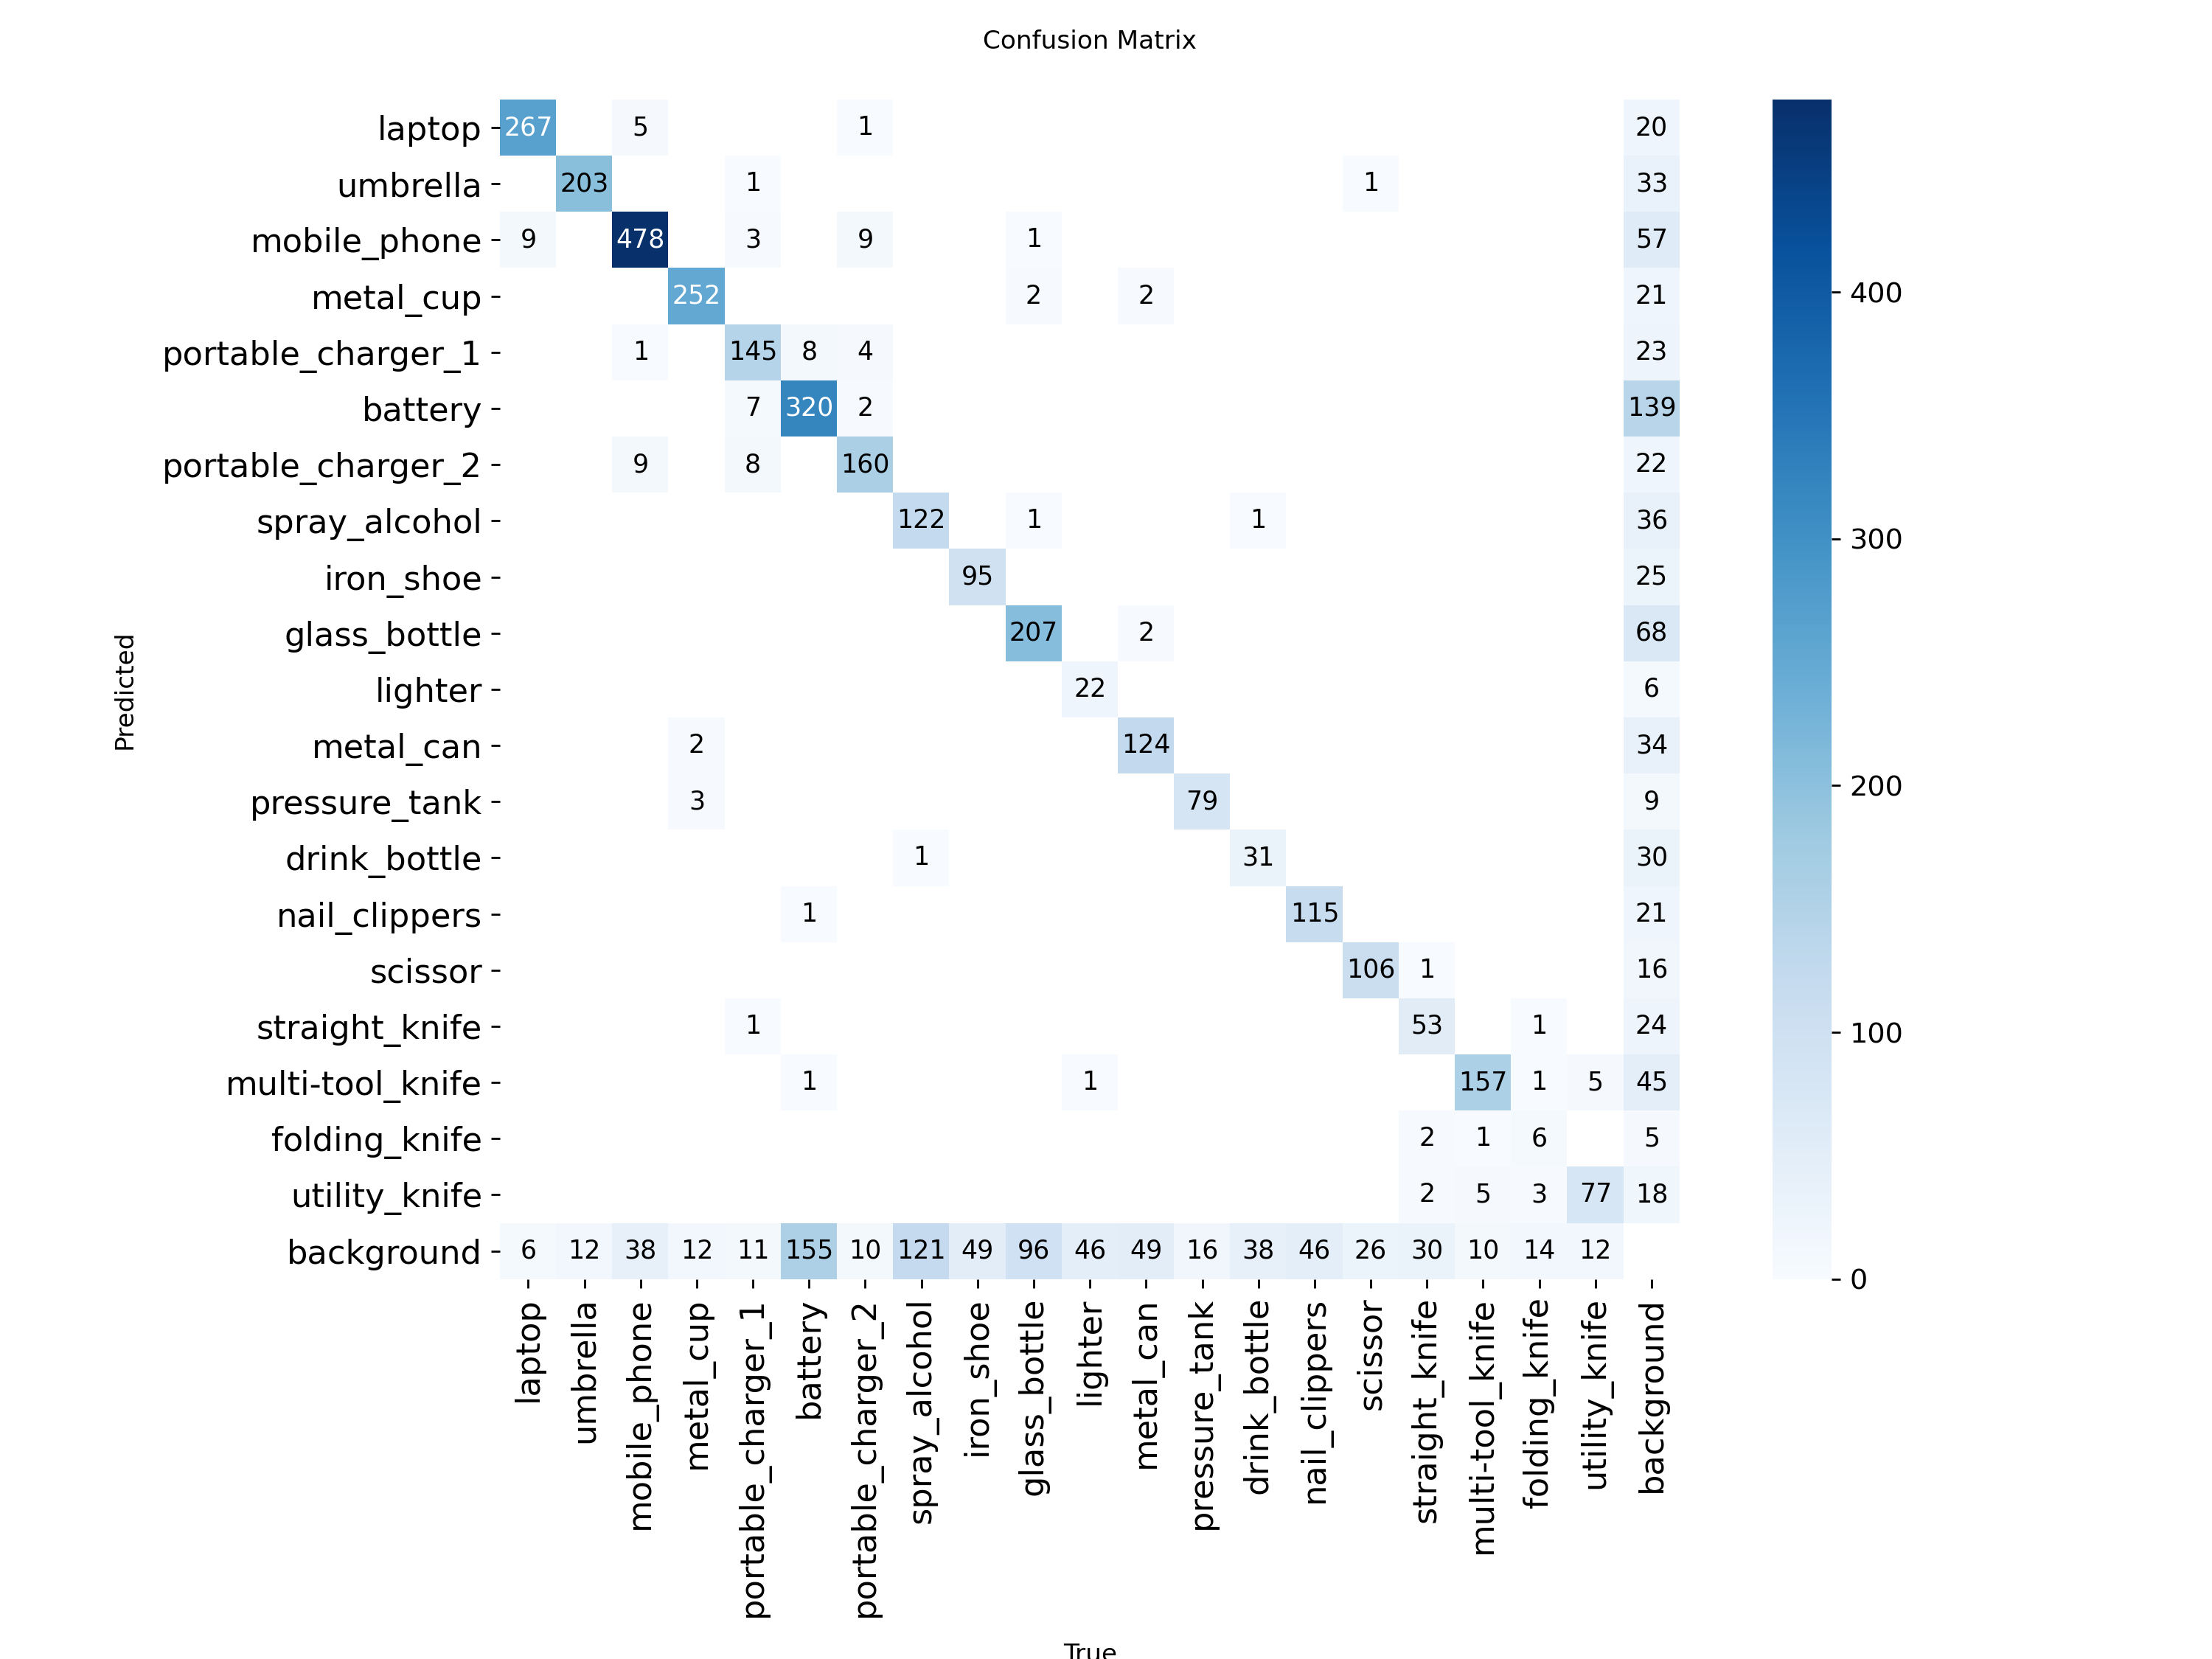

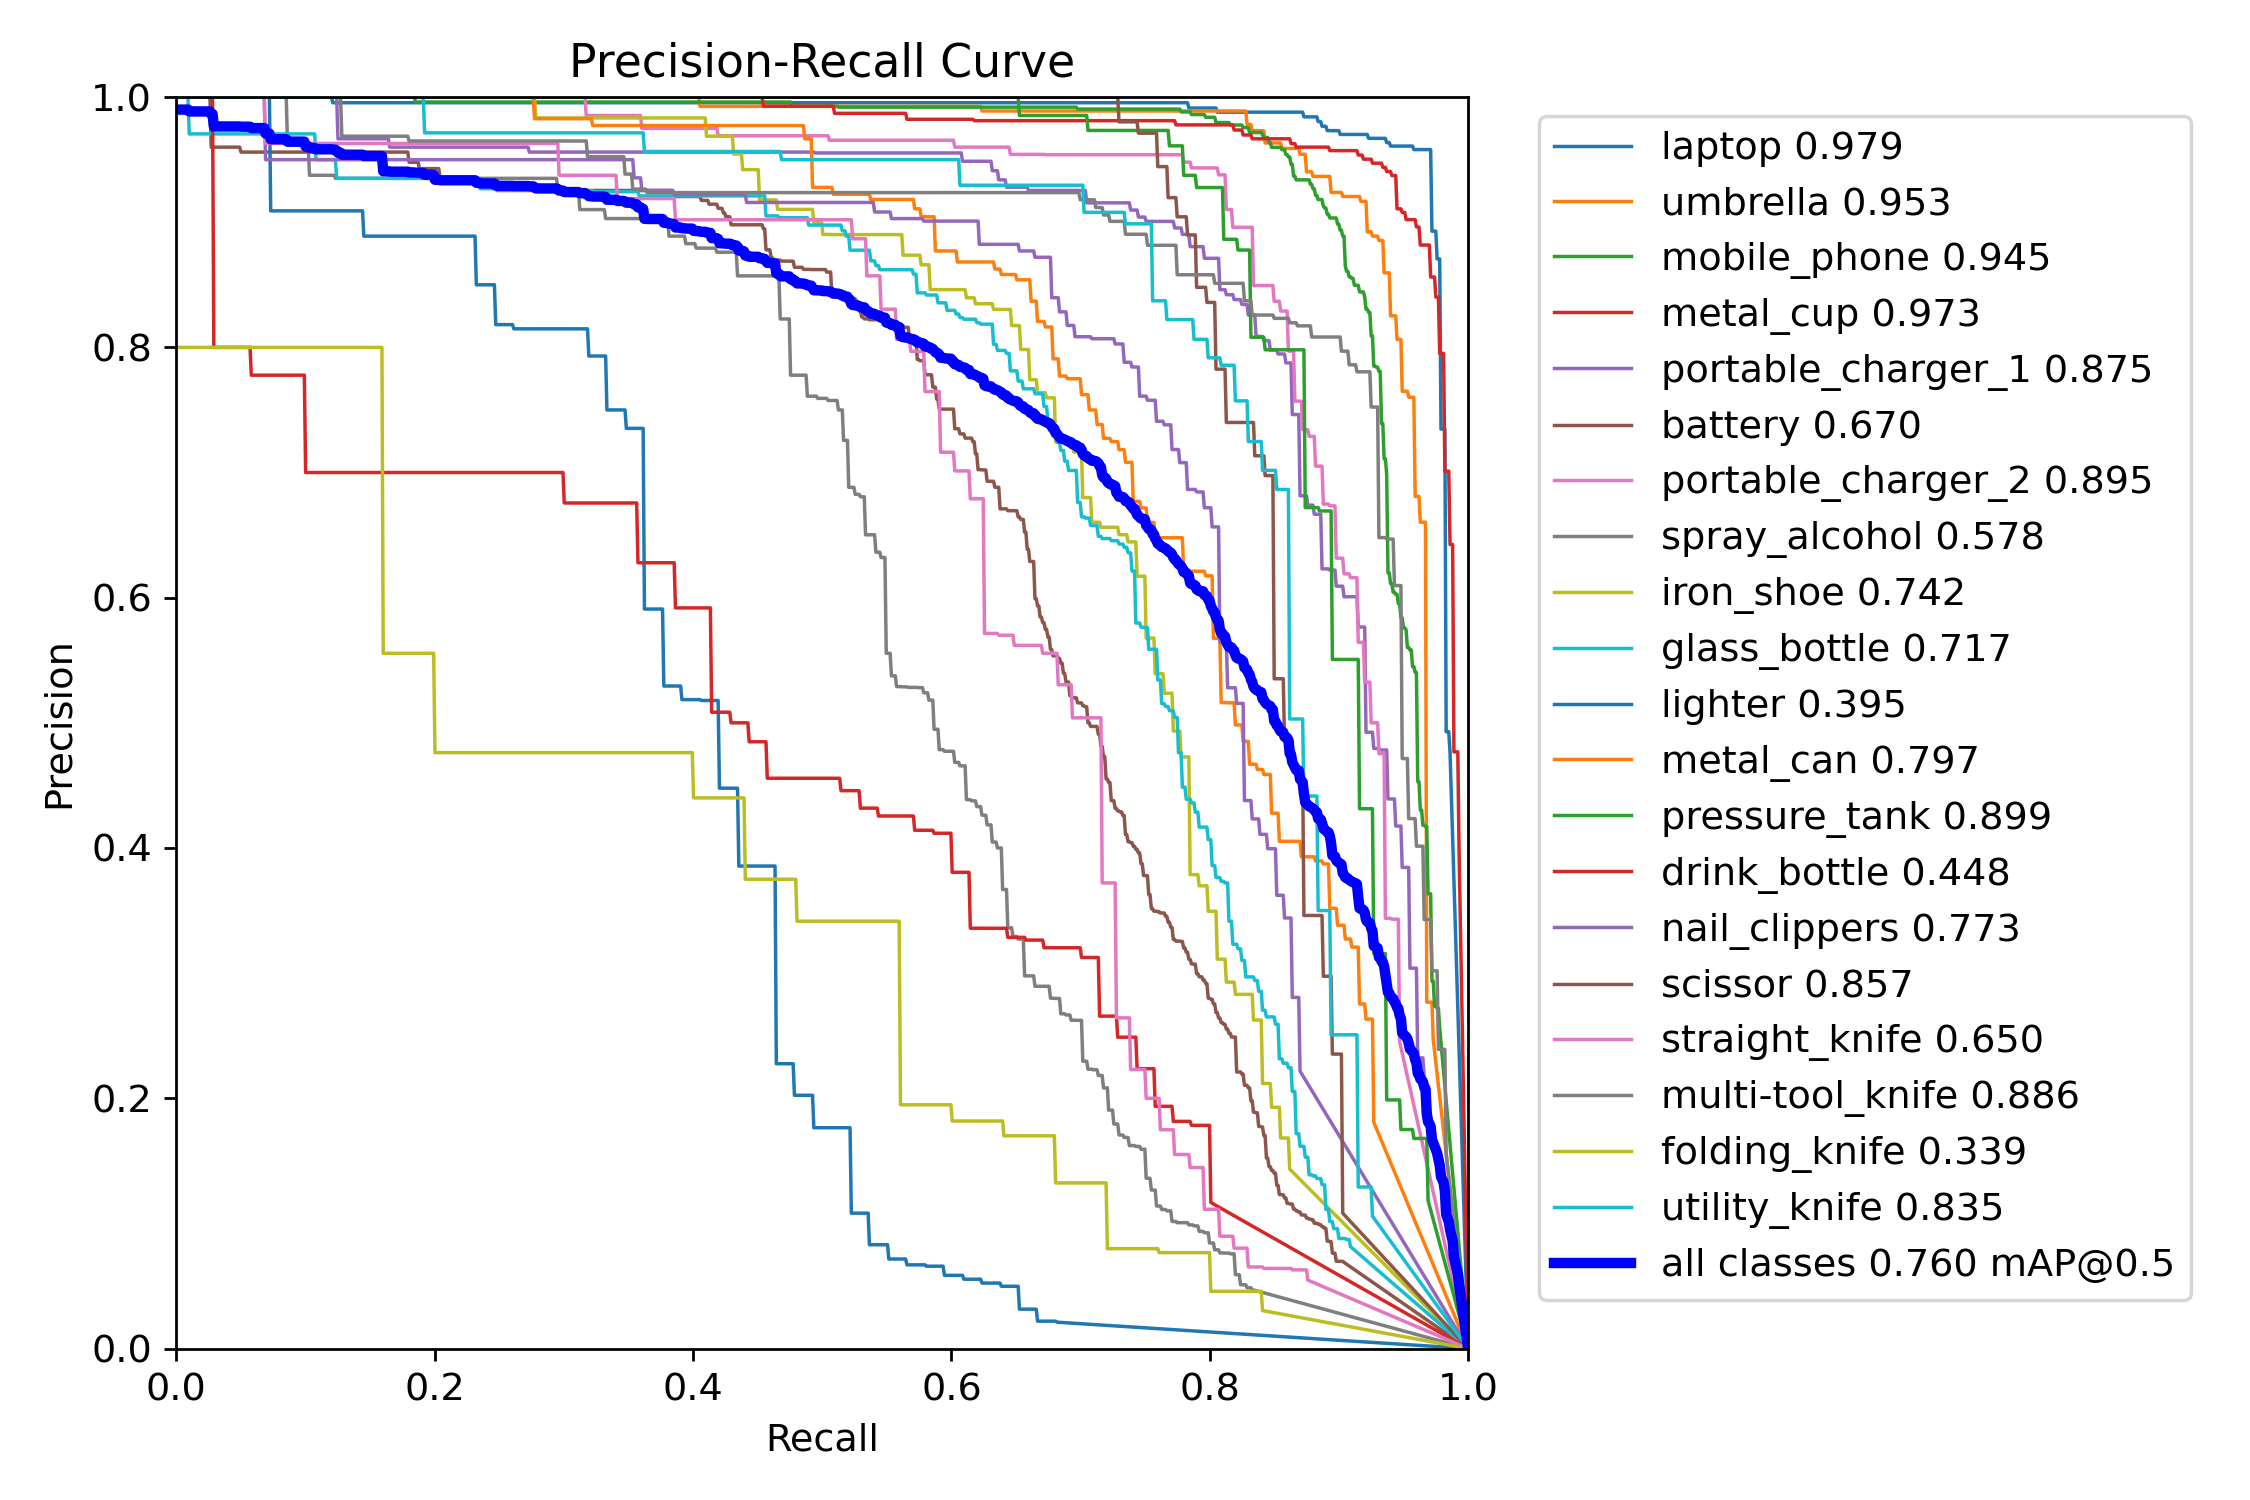

In [7]:
print("--- Evaluating MEDIUM Model (YOLOv10m) ---")
model_medium = YOLO(medium_model_path)

# --- Validation Set ---
print("\n--- On Validation Set ---")
val_metrics_medium = model_medium.val(data=yaml_path, split='val', name='yolov10m-val')
print_metrics(val_metrics_medium, 'YOLOv10m', 'FSOD', 'Validation')
# Display Plots for validation
results_dir_medium_val = 'runs/detect/yolov10m-val'
display(Image(filename=f'{results_dir_medium_val}/confusion_matrix.png'))
display(Image(filename=f'{results_dir_medium_val}/PR_curve.png'))

# --- New Test Set ---
print("\n--- On New Test Set ---")
newtest_metrics_medium = model_medium.val(data=yaml_path, split='newtest', name='yolov10m-newtest')
print_metrics(newtest_metrics_medium, 'YOLOv10m', 'FSOD', 'New Test')
# Display Plots for newtest
results_dir_medium_newtest = 'runs/detect/yolov10m-newtest'
display(Image(filename=f'{results_dir_medium_newtest}/confusion_matrix.png'))
display(Image(filename=f'{results_dir_medium_newtest}/PR_curve.png'))



--- Evaluating LARGE Model (YOLOv10l) ---

--- On Validation Set ---
Ultralytics 8.3.155 🚀 Python-3.11.11 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLOv10l summary (fused): 174 layers, 24,324,748 parameters, 0 gradients, 120.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 317.6±182.3 MB/s, size: 152.0 KB)


val: Scanning /kaggle/input/object-detection-lydia/FSOD/FSOD/val/labels... 1233 images, 0 backgrounds, 0 corrupt: 100%|██████████| 1233/1233 [00:01<00:00, 1184.51it/s]

WARNING ⚠️ val: Cache directory /kaggle/input/object-detection-lydia/FSOD/FSOD/val is not writeable, cache not saved.



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 78/78 [00:40<00:00,  1.93it/s]
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


                   all       1233       4070      0.807      0.711      0.778      0.559
                laptop        217        269      0.889      0.955      0.967      0.861
              umbrella        179        219      0.853      0.845      0.888      0.642
          mobile_phone        337        540      0.885       0.87      0.934      0.765
             metal_cup        228        270      0.921      0.907      0.967      0.826
    portable_charger_1        149        177       0.83      0.853      0.926      0.697
               battery        319        480      0.731      0.619      0.705      0.413
    portable_charger_2        144        199      0.851      0.809      0.896      0.665
         spray_alcohol        168        249      0.766      0.486      0.603      0.383
             iron_shoe         80        166      0.839       0.69      0.767      0.483
          glass_bottle        174        298      0.777      0.658      0.744      0.484
               lighte

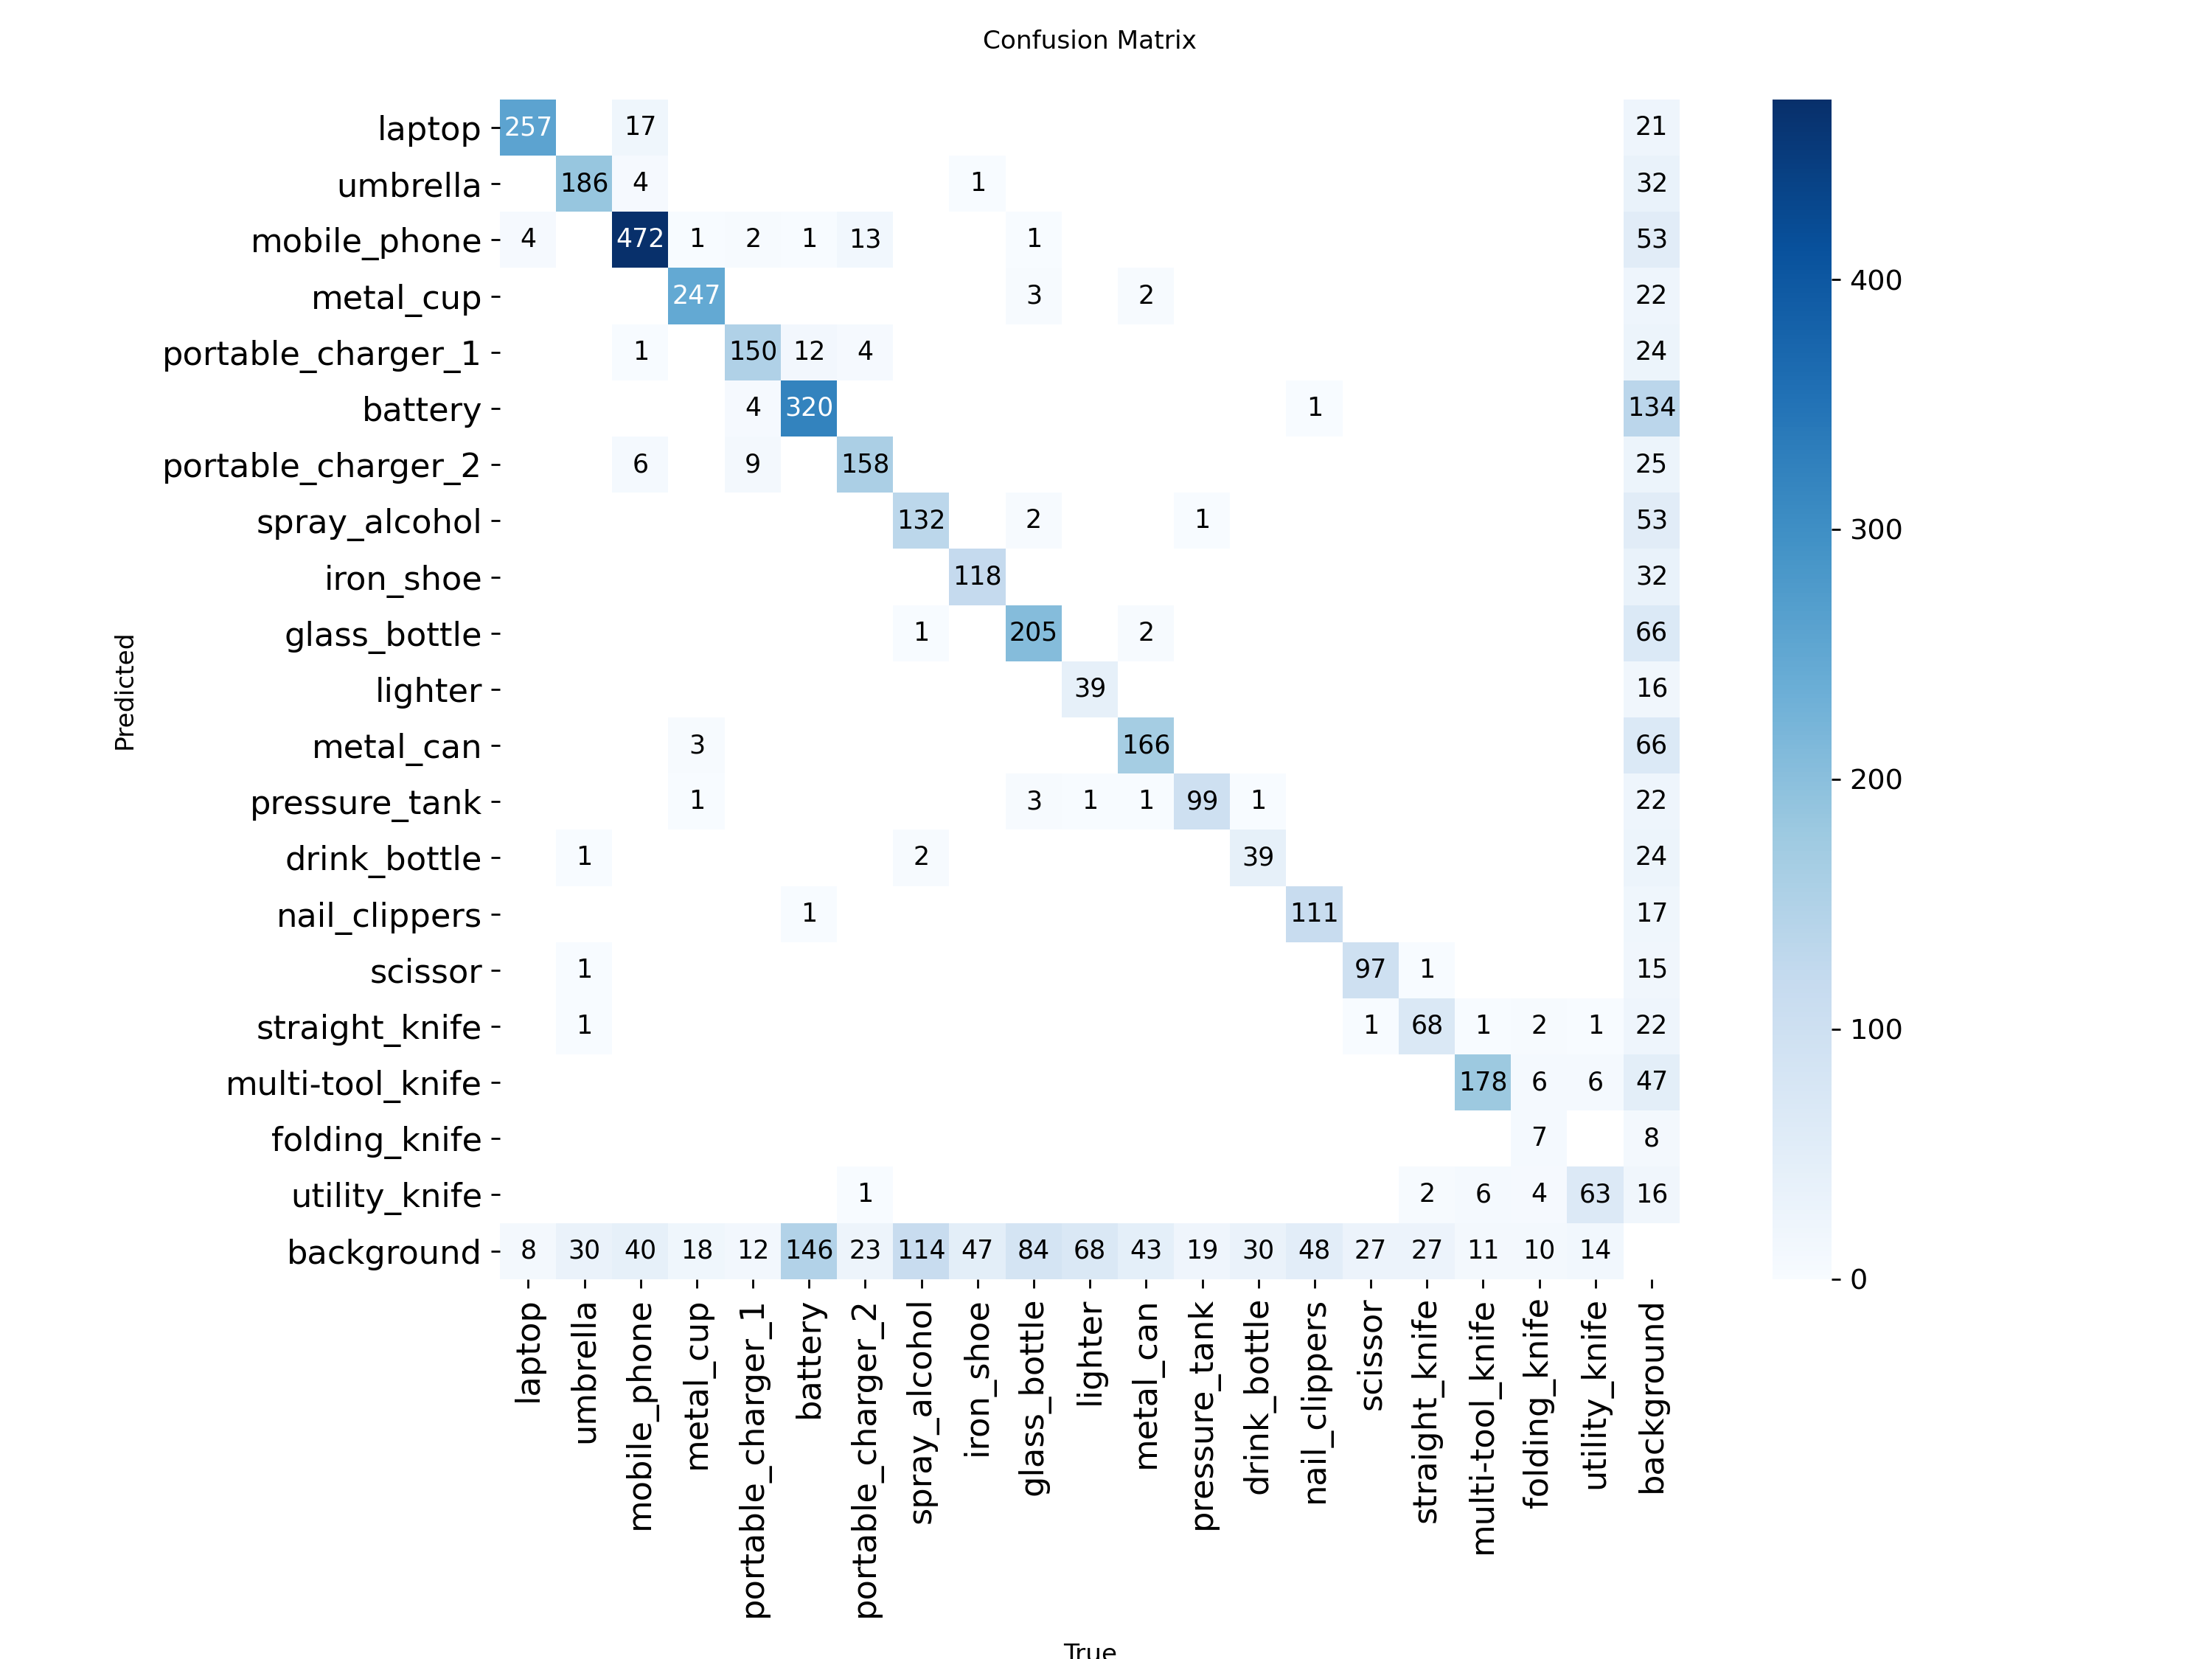

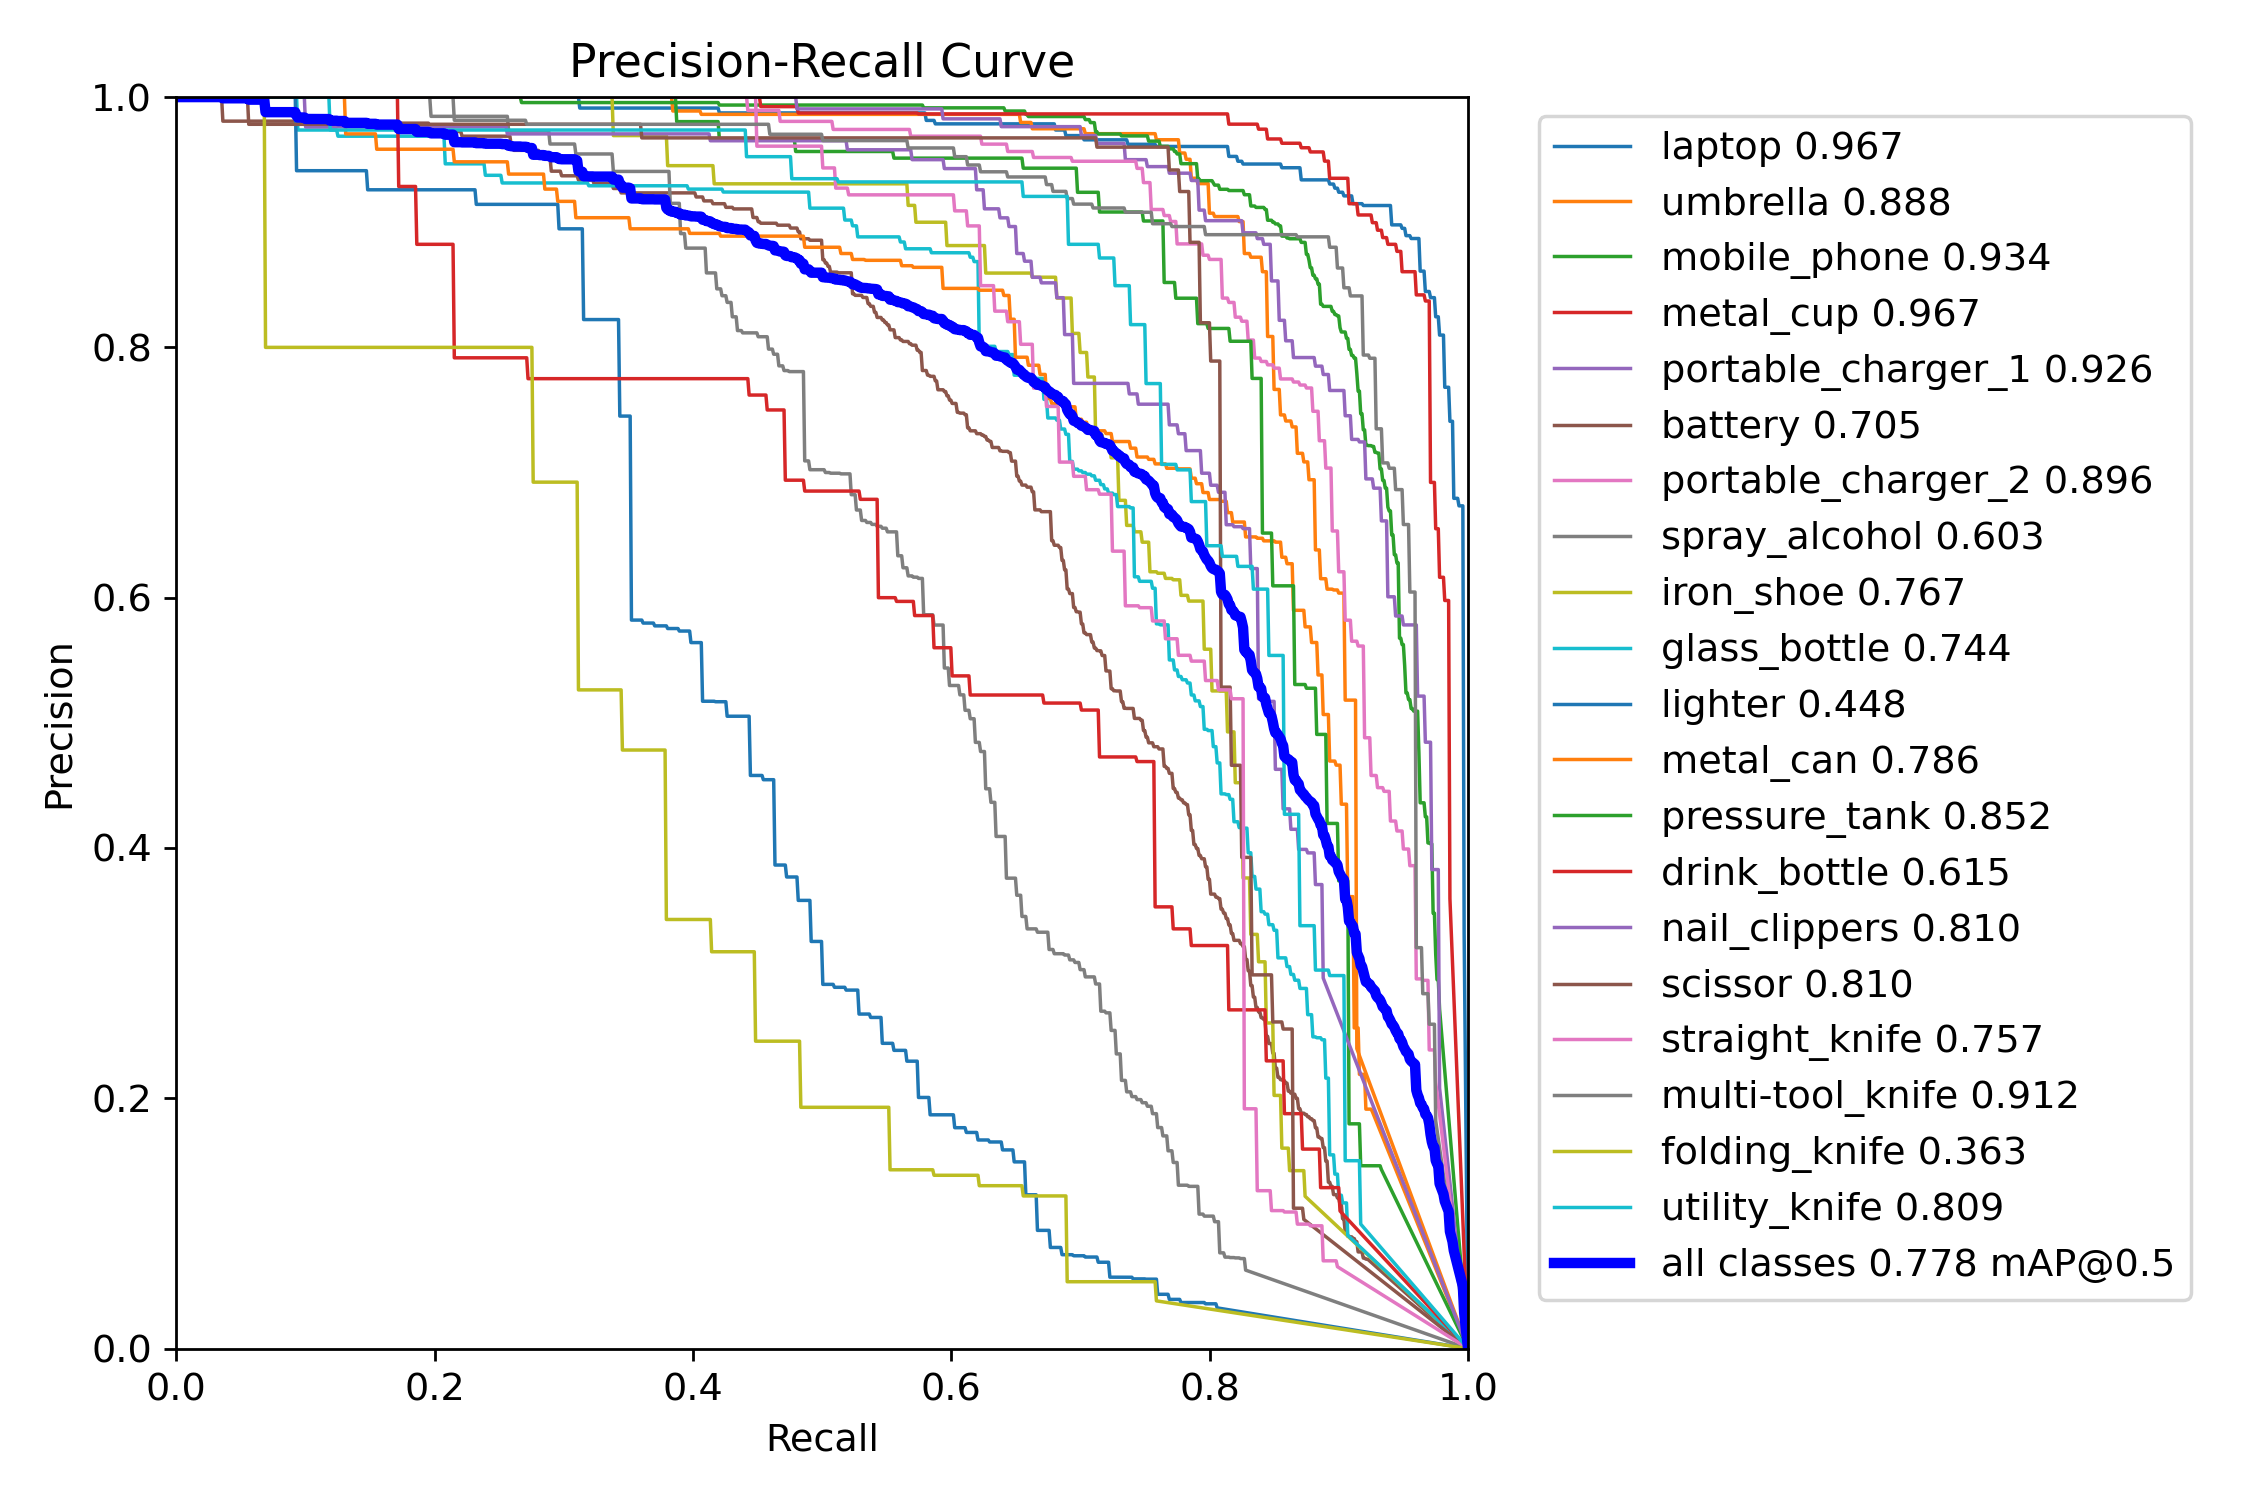


--- On New Test Set ---
Ultralytics 8.3.155 🚀 Python-3.11.11 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 391.5±208.7 MB/s, size: 233.9 KB)


val: Scanning /kaggle/input/object-detection-lydia/FSOD/FSOD/newtest/labels... 1232 images, 1 backgrounds, 0 corrupt: 100%|██████████| 1233/1233 [00:01<00:00, 956.16it/s] 

WARNING ⚠️ val: Cache directory /kaggle/input/object-detection-lydia/FSOD/FSOD/newtest is not writeable, cache not saved.



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 78/78 [00:43<00:00,  1.79it/s]
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


                   all       1233       3924      0.821      0.701       0.77      0.555
                laptop        238        282      0.939      0.954      0.976       0.89
              umbrella        174        215      0.891      0.935      0.965      0.698
          mobile_phone        338        531      0.918      0.889      0.951      0.786
             metal_cup        240        269      0.926      0.937      0.967      0.866
    portable_charger_1        147        176      0.837      0.841      0.904      0.672
               battery        308        485      0.758      0.575      0.663      0.375
    portable_charger_2        143        186      0.899      0.833      0.905      0.706
         spray_alcohol        173        244      0.851       0.48      0.597      0.372
             iron_shoe         71        144      0.809      0.589      0.711      0.449
          glass_bottle        165        307      0.798      0.648      0.752      0.494
               lighte

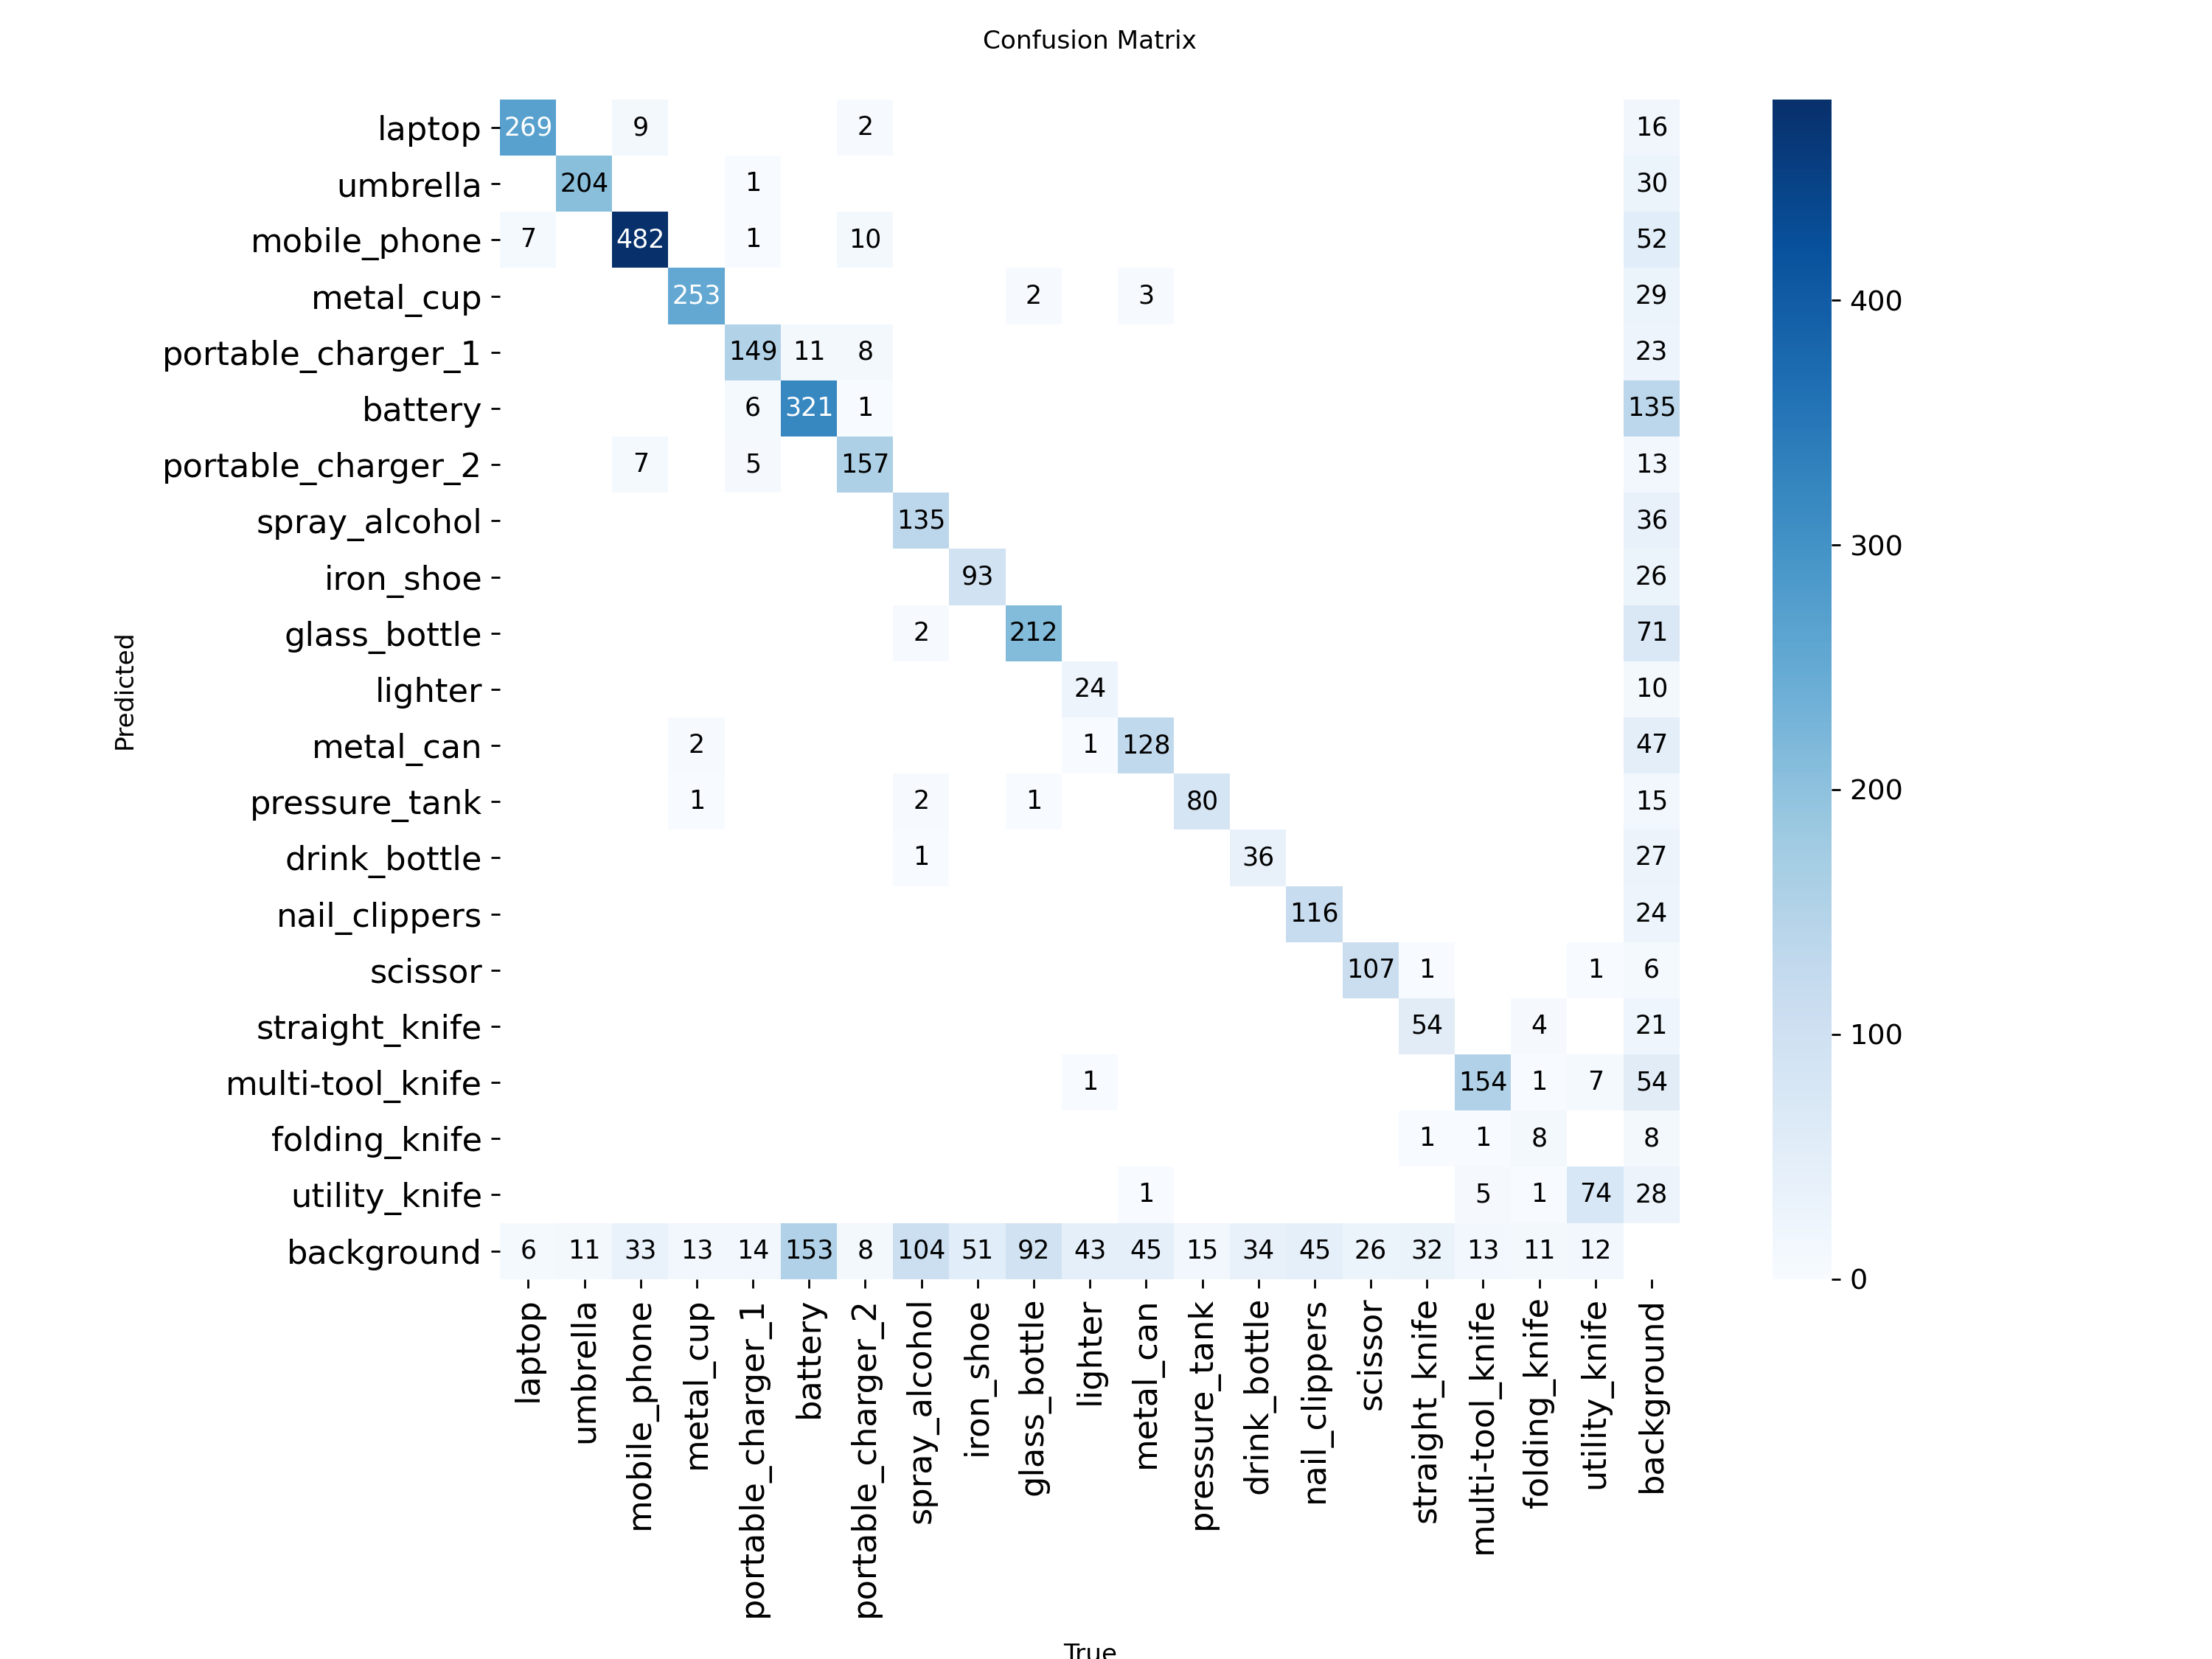

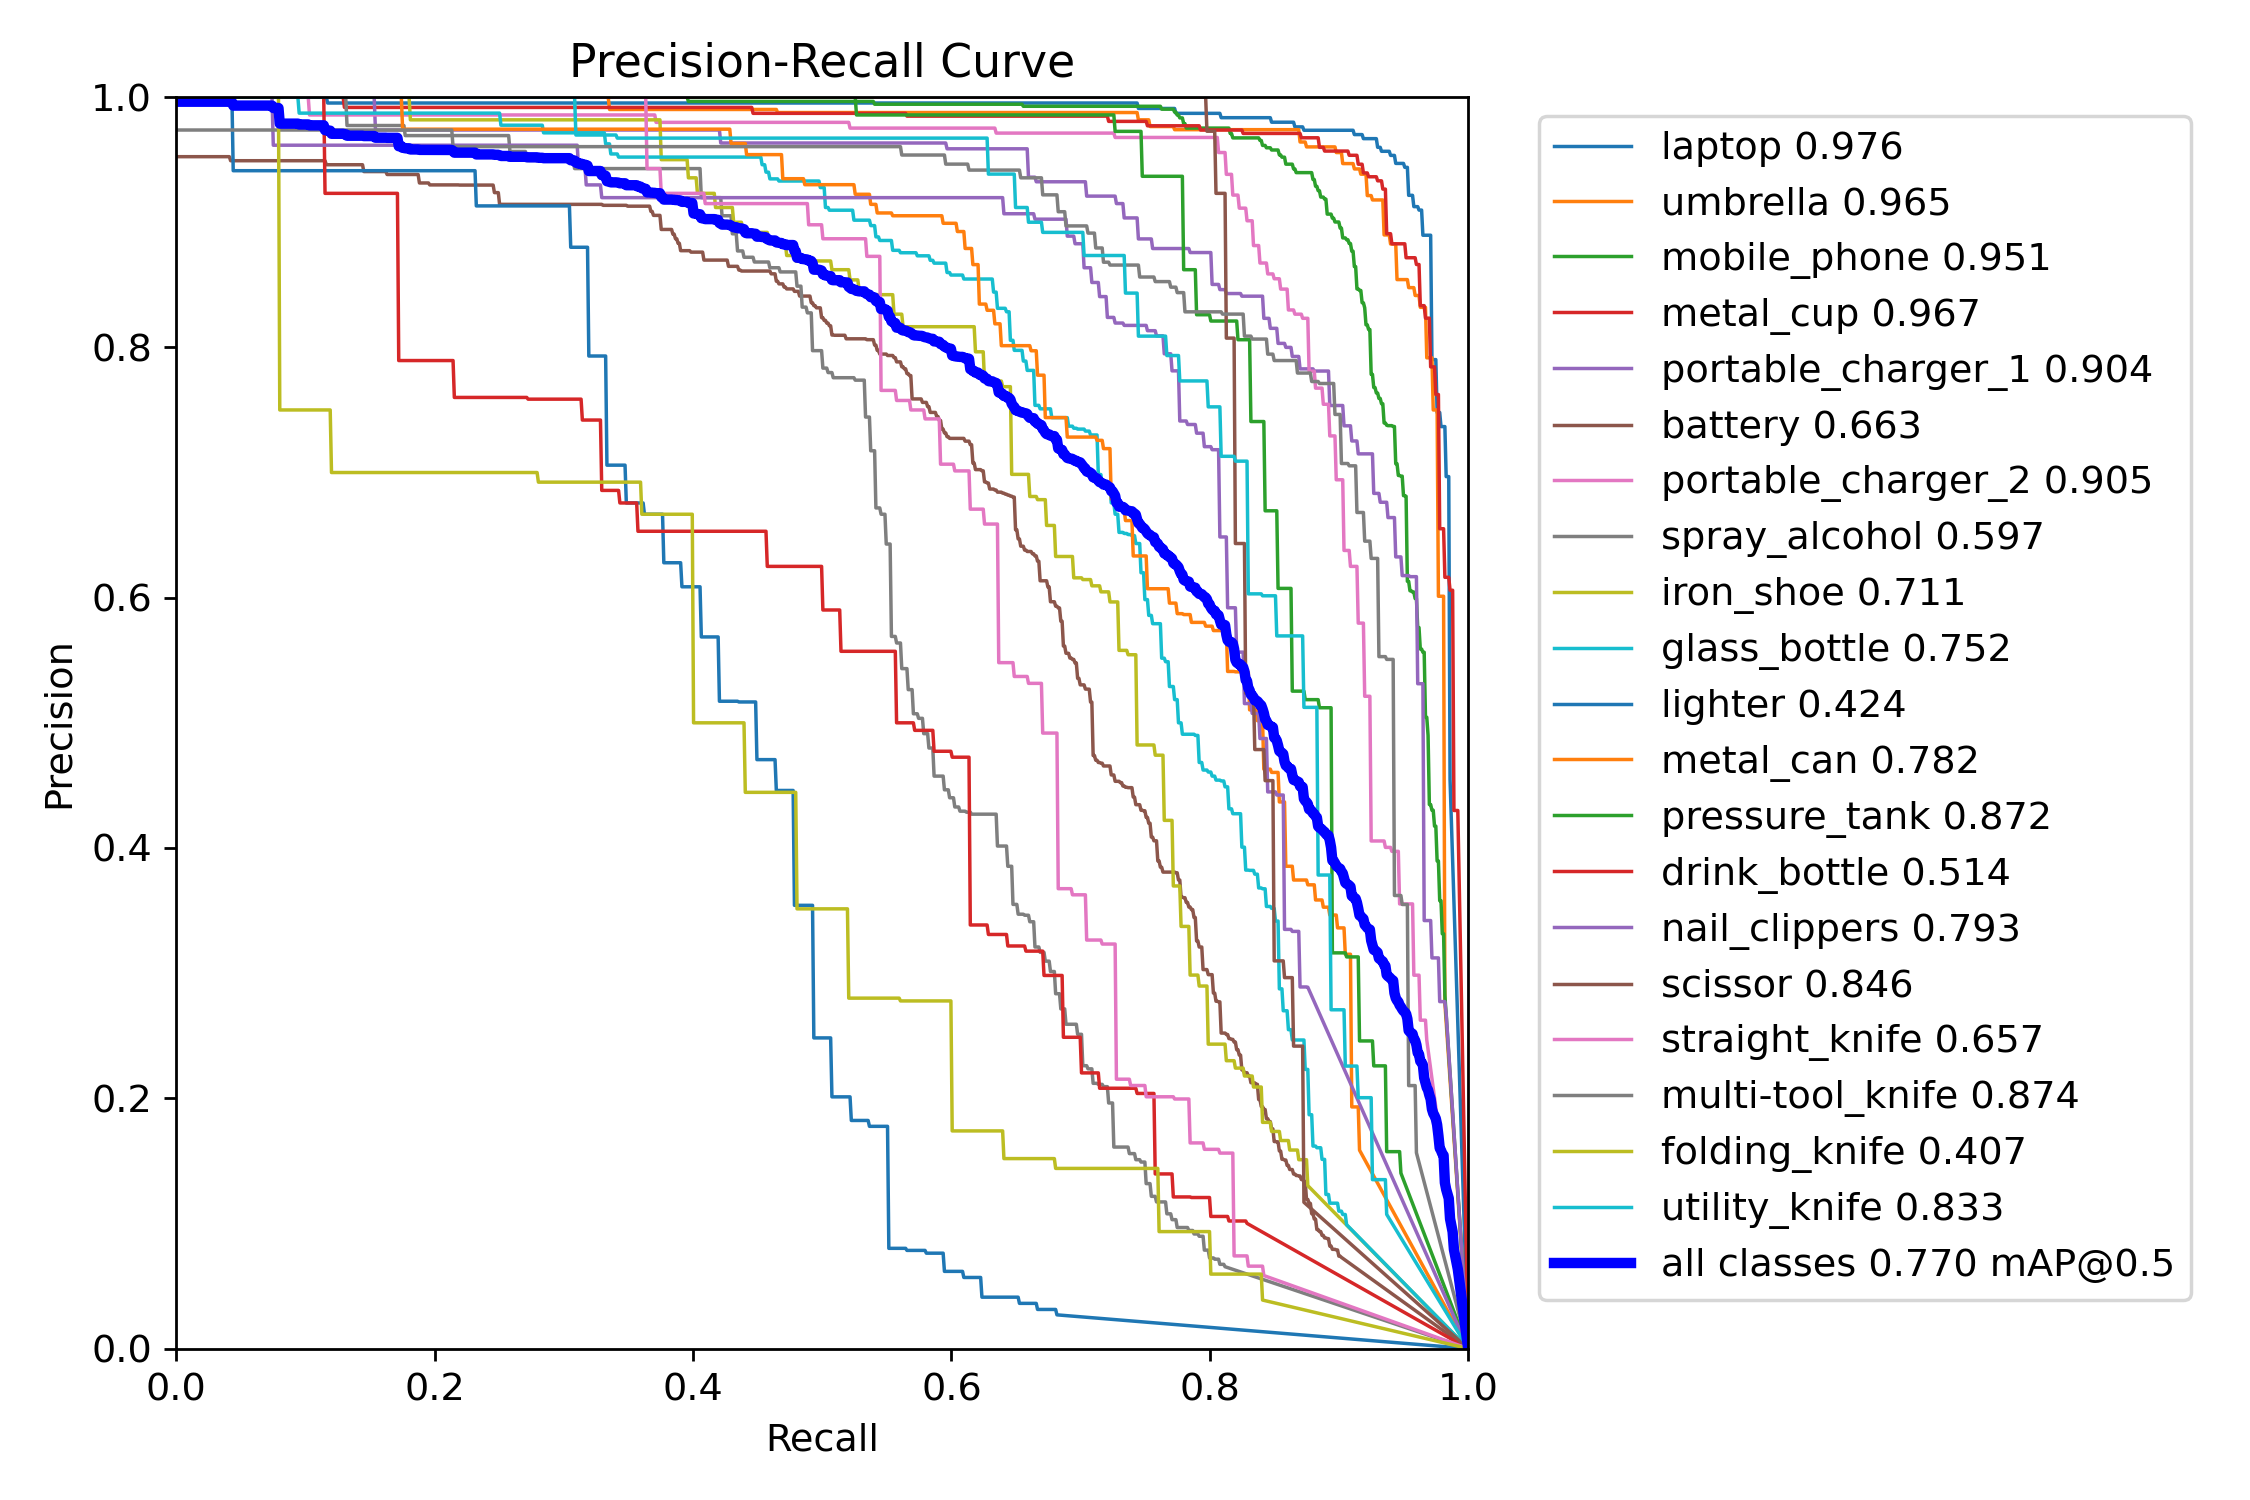

In [8]:
print("\n\n--- Evaluating LARGE Model (YOLOv10l) ---")
model_large = YOLO(large_model_path)

# --- Validation Set ---
print("\n--- On Validation Set ---")
val_metrics_large = model_large.val(data=yaml_path, split='val', name='yolov10l-val')
print_metrics(val_metrics_large, 'YOLOv10l', 'FSOD', 'Validation')
# Display Plots for validation
results_dir_large_val = 'runs/detect/yolov10l-val'
display(Image(filename=f'{results_dir_large_val}/confusion_matrix.png'))
display(Image(filename=f'{results_dir_large_val}/PR_curve.png'))


# --- New Test Set ---
print("\n--- On New Test Set ---")
newtest_metrics_large = model_large.val(data=yaml_path, split='newtest', name='yolov10l-newtest')
print_metrics(newtest_metrics_large, 'YOLOv10l', 'FSOD', 'New Test')
# Display Plots for newtest
results_dir_large_newtest = 'runs/detect/yolov10l-newtest'
display(Image(filename=f'{results_dir_large_newtest}/confusion_matrix.png'))
display(Image(filename=f'{results_dir_large_newtest}/PR_curve.png'))